In [1]:
%pip install psycopg2-binary pandas nltk matplotlib

## 1. Carga de datos

Crear un archivo `.env` local con `DB_NAME`, `DB_USER`, `DB_PASSWORD`, `DB_HOST=127.0.0.1` y `DB_PORT=55433`. Desde la carpeta `Lab7BD2`, iniciar PostgreSQL con `docker compose up -d`. El notebook lee `news_es.csv` y `stoplist.txt` de esta misma carpeta.


In [2]:
import csv
import os
from pathlib import Path

import pandas as pd
import psycopg2

env_file = Path('.env')
if not env_file.is_file():
    raise FileNotFoundError('Falta el archivo .env en Lab7BD2')
env_values = dict(
    line.split('=', 1)
    for line in env_file.read_text(encoding='utf-8').splitlines()
    if '=' in line and not line.startswith('#')
)
variables = ['DB_NAME', 'DB_USER', 'DB_PASSWORD', 'DB_HOST', 'DB_PORT']
config = {name: os.getenv(name) or env_values.get(name) for name in variables}
missing = [name for name, value in config.items() if not value]
if missing:
    raise ValueError('Falta configurar: ' + ', '.join(missing))

source_dir = Path.cwd()
news_file = source_dir / 'news_es.csv'
stoplist_file = source_dir / 'stoplist.txt'
if not news_file.is_file() or not stoplist_file.is_file():
    raise FileNotFoundError('Faltan news_es.csv o stoplist.txt en Lab7BD2')


def connect_db():
    return psycopg2.connect(
        dbname=config['DB_NAME'],
        user=config['DB_USER'],
        password=config['DB_PASSWORD'],
        host=config['DB_HOST'],
        port=config['DB_PORT'],
        connect_timeout=10
    )


def load_data():
    conn = connect_db()
    try:
        with conn.cursor() as cur:
            cur.execute("""
                CREATE TABLE IF NOT EXISTS noticias (
                    id SERIAL PRIMARY KEY,
                    url TEXT,
                    contenido TEXT,
                    categoria VARCHAR(50),
                    bag_of_words JSONB
                );
                CREATE TABLE IF NOT EXISTS stopwords (
                    id SERIAL PRIMARY KEY,
                    word TEXT UNIQUE NOT NULL
                );
            """)

            cur.execute('SELECT COUNT(*) FROM noticias')
            if cur.fetchone()[0] == 0:
                with news_file.open('r', encoding='utf-8-sig', newline='') as data:
                    cur.copy_expert(
                        'COPY noticias (url, contenido, categoria) FROM STDIN '
                        'WITH (FORMAT csv, HEADER true, FORCE_NOT_NULL (contenido))',
                        data
                    )

            cur.execute('SELECT COUNT(*) FROM stopwords')
            if cur.fetchone()[0] == 0:
                with stoplist_file.open('r', encoding='utf-8-sig') as data:
                    cur.copy_expert('COPY stopwords (word) FROM STDIN', data)

            with news_file.open('r', encoding='utf-8-sig', newline='') as data:
                expected_news = [
                    (row['url'], row['news'], row['Type'])
                    for row in csv.DictReader(data)
                ]
            cur.execute('SELECT url, contenido, categoria FROM noticias ORDER BY id')
            if cur.fetchall() != expected_news:
                raise ValueError('La tabla noticias no coincide con news_es.csv')

            expected_words = stoplist_file.read_text(encoding='utf-8-sig').splitlines()
            cur.execute('SELECT word FROM stopwords ORDER BY id')
            if [row[0] for row in cur.fetchall()] != expected_words:
                raise ValueError('La tabla stopwords no coincide con stoplist.txt')

        conn.commit()
        return len(expected_news), len(expected_words)
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()


def fetch_data():
    conn = connect_db()
    try:
        return pd.read_sql('SELECT id, contenido FROM noticias ORDER BY id', conn)
    finally:
        conn.close()


news_count, stopword_count = load_data()
noticias_df = fetch_data()
print(f'Noticias: {news_count}; stopwords: {stopword_count}')
display(noticias_df.head(10))


Noticias: 1217; stopwords: 608


,id,contenido
0,1,Durante el foro La banca articulador empresari...
1,2,El regulador de valores de China dijo el domin...
2,3,En una industria históricamente masculina como...
3,4,Con el dato de marzo el IPC interanual encaden...
4,5,Ayer en Cartagena se dio inicio a la versión n...
5,6,El emprendimiento del sector inmobiliario Rent...
6,7,El país tiene pendiente generar más y mejores ...
7,8,En el 'podcast' tenemos el placer de entrevist...
8,9,"El factor humano, normalmente identificado com..."
9,10,Los perfiles que se demandan en un banco han e...


## 2. Preprocesamiento

### Bag of Words

In [3]:
from collections import Counter

from nltk.stem.snowball import SnowballStemmer
from nltk.tokenize import word_tokenize
from psycopg2.extras import Json

conn = connect_db()
try:
    with conn.cursor() as cur:
        cur.execute('SELECT word FROM stopwords')
        stop_words = {row[0] for row in cur.fetchall()}
finally:
    conn.close()

stemmer = SnowballStemmer('spanish')


def preprocess(text):
    if not isinstance(text, str):
        return []
    tokens = word_tokenize(text.lower(), language='spanish', preserve_line=True)
    return [
        stemmer.stem(token)
        for token in tokens
        if token.isalpha() and token not in stop_words
    ]


def compute_bow(text):
    return dict(Counter(preprocess(text)))


def update_bow_in_db(dataframe):
    conn = connect_db()
    try:
        with conn:
            with conn.cursor() as cur:
                for row in dataframe.itertuples(index=False):
                    cur.execute(
                        'UPDATE noticias SET bag_of_words = %s WHERE id = %s',
                        (Json(compute_bow(row.contenido)), int(row.id))
                    )
    finally:
        conn.close()


def fetch_data_bow():
    conn = connect_db()
    try:
        return pd.read_sql(
            'SELECT id, contenido, bag_of_words FROM noticias ORDER BY id', conn
        )
    finally:
        conn.close()


update_bow_in_db(noticias_df)
noticias_bow_df = fetch_data_bow()
display(noticias_bow_df.head(10))


,id,contenido,bag_of_words
0,1,Durante el foro La banca articulador empresari...,"{'aca': 1, 'adn': 1, 'cas': 1, 'for': 1, 'ret'..."
1,2,El regulador de valores de China dijo el domin...,"{'dat': 1, 'deb': 1, 'inc': 1, 'med': 1, 'mes'..."
2,3,En una industria históricamente masculina como...,"{'go': 1, 'air': 1, 'baj': 1, 'ceo': 2, 'hij':..."
3,4,Con el dato de marzo el IPC interanual encaden...,"{'agu': 1, 'car': 2, 'dat': 2, 'ine': 2, 'ipc'..."
4,5,Ayer en Cartagena se dio inicio a la versión n...,"{'agu': 1, 'cup': 2, 'deb': 2, 'for': 4, 'got'..."
5,6,El emprendimiento del sector inmobiliario Rent...,"{'big': 1, 'ceo': 1, 'dat': 1, 'sum': 1, 'cerr..."
6,7,El país tiene pendiente generar más y mejores ...,"{'ve': 1, 'baj': 1, 'cas': 2, 'dat': 1, 'dej':..."
7,8,En el 'podcast' tenemos el placer de entrevist...,"{'agil': 4, 'habl': 1, 'mund': 1, 'nach': 3, '..."
8,9,"El factor humano, normalmente identificado com...","{'u': 1, 'ali': 2, 'bas': 1, 'cas': 2, 'cin': ..."
9,10,Los perfiles que se demandan en un banco han e...,"{'are': 1, 'cab': 1, 'cas': 1, 'dat': 2, 'pud'..."


## 3. Búsqueda booleana


### 3.1 Búsqueda lineal


In [4]:
import re


def query_term(text):
    terms = preprocess(text)
    if len(terms) != 1:
        raise ValueError('Cada operando debe contener un término válido')
    return terms[0]


def boolean_search_linear(query, dataframe):
    parts = re.split(r'\s+(AND-NOT|AND|OR)\s+', query.strip(), flags=re.IGNORECASE)
    if len(parts) != 3:
        raise ValueError('Usar una consulta de dos términos con AND, OR o AND-NOT')

    left, operator, right = parts
    left = query_term(left)
    right = query_term(right)
    results = []
    for row in dataframe.itertuples(index=False):
        bow = row.bag_of_words
        has_left = left in bow
        has_right = right in bow
        if (operator.upper() == 'AND' and has_left and has_right or
            operator.upper() == 'OR' and (has_left or has_right) or
            operator.upper() == 'AND-NOT' and has_left and not has_right):
            results.append(row.id)
    return results


linear_queries = [
    'economía AND inflación',
    'banca OR finanzas',
    'tecnología AND-NOT inflación',
]
for query in linear_queries:
    results = boolean_search_linear(query, noticias_bow_df)
    print(query, '->', len(results), 'noticias; IDs:', results[:10])


economía AND inflación -> 237 noticias; IDs: [5, 7, 18, 21, 24, 32, 33, 34, 37, 39]
banca OR finanzas -> 536 noticias; IDs: [1, 2, 5, 9, 10, 12, 13, 15, 16, 17]
tecnología AND-NOT inflación -> 303 noticias; IDs: [12, 13, 14, 15, 16, 17, 19, 20, 23, 28]


### 3.2 Índice invertido


In [5]:
import math


def tf_weight(frequency):
    return math.log10(1 + frequency)


class InvertedIndex:
    def __init__(self):
        self.index = {}
        self.idf = {}
        self.length = {}
        self._docs = {}
        self._bows = {}

    def build_from_db(self):
        self.index = {}
        self.idf = {}
        self.length = {}
        self._docs = {}
        self._bows = {}
        conn = connect_db()
        try:
            with conn.cursor() as cur:
                cur.execute('SELECT id, contenido, bag_of_words FROM noticias ORDER BY id')
                rows = cur.fetchall()
        finally:
            conn.close()

        for doc_id, content, bow in rows:
            if bow is None:
                raise ValueError(f'Falta el Bag of Words de la noticia {doc_id}')
            self._docs[doc_id] = content
            self._bows[doc_id] = bow
            for term, frequency in bow.items():
                self.index.setdefault(term, []).append((doc_id, frequency))

        doc_count = len(rows)
        lengths_squared = {doc_id: 0.0 for doc_id in self._docs}
        for term, postings in self.index.items():
            weight = math.log10(doc_count / len(postings))
            self.idf[term] = weight
            for doc_id, frequency in postings:
                lengths_squared[doc_id] += (tf_weight(frequency) * weight) ** 2
        self.length = {
            doc_id: math.sqrt(value) for doc_id, value in lengths_squared.items()
        }

    def L(self, word):
        return self.index.get(query_term(word), [])

    def showDocument(self, doc_id, max_chars=80):
        return self._docs.get(doc_id, '')[:max_chars] + '...'

    def showDocuments(self, posting_list, max_chars=80):
        return [self.showDocument(doc_id, max_chars) for doc_id, _ in posting_list]


def AND(list1, list2):
    result = []
    i = j = 0
    while i < len(list1) and j < len(list2):
        if list1[i][0] == list2[j][0]:
            result.append(list1[i])
            i += 1
            j += 1
        elif list1[i][0] < list2[j][0]:
            i += 1
        else:
            j += 1
    return result


def OR(list1, list2):
    result = []
    i = j = 0
    while i < len(list1) and j < len(list2):
        if list1[i][0] == list2[j][0]:
            result.append((list1[i][0], max(list1[i][1], list2[j][1])))
            i += 1
            j += 1
        elif list1[i][0] < list2[j][0]:
            result.append(list1[i])
            i += 1
        else:
            result.append(list2[j])
            j += 1
    result.extend(list1[i:])
    result.extend(list2[j:])
    return result


def AND_NOT(list1, list2):
    result = []
    i = j = 0
    while i < len(list1) and j < len(list2):
        if list1[i][0] == list2[j][0]:
            i += 1
            j += 1
        elif list1[i][0] < list2[j][0]:
            result.append(list1[i])
            i += 1
        else:
            j += 1
    result.extend(list1[i:])
    return result


idx = InvertedIndex()
idx.build_from_db()

indexed_tests = [
    ('economía AND inflación', AND(idx.L('economía'), idx.L('inflación'))),
    ('banca OR finanzas', OR(idx.L('banca'), idx.L('finanzas'))),
    ('tecnología AND-NOT inflación', AND_NOT(idx.L('tecnología'), idx.L('inflación'))),
    ('sostenibilidad AND ambiente AND renovables', AND(idx.L('sostenibilidad'), AND(idx.L('ambiente'), idx.L('renovables')))),
    ('tecnología AND (banca OR finanzas)', AND(idx.L('tecnología'), OR(idx.L('banca'), idx.L('finanzas')))),
    ('(economía OR crecimiento) AND-NOT inflación', AND_NOT(OR(idx.L('economía'), idx.L('crecimiento')), idx.L('inflación'))),
]

for query, postings in indexed_tests:
    print(query, '->', len(postings), 'noticias')
    print(idx.showDocuments(postings[:3]))

for query, postings in indexed_tests[:3]:
    assert boolean_search_linear(query, noticias_bow_df) == [doc_id for doc_id, _ in postings]


economía AND inflación -> 237 noticias
['Ayer en Cartagena se dio inicio a la versión número 56 de la Convención Bancaria...', 'El país tiene pendiente generar más y mejores acciones para contrarrestar la pob...', 'Los precios al consumidor subieron 238 en agosto respecto al año anterior impuls...']
banca OR finanzas -> 536 noticias
['Durante el foro La banca articulador empresarial para el desarrollo sostenible e...', 'El regulador de valores de China dijo el domingo que buscará una cooperación más...', 'Ayer en Cartagena se dio inicio a la versión número 56 de la Convención Bancaria...']
tecnología AND-NOT inflación -> 303 noticias
['BBVA ha presentado BBVA Spark, su propuesta integral de servicios financieros pa...', 'Con acciones que se comprometen con el desarrollo sostenible, ambas organizacion...', 'Las plataformas de domicilios fueron uno de los jugadores más importantes de la ...']
sostenibilidad AND ambiente AND renovables -> 5 noticias
['Esta tipología de energía, clave para

## 4. Similitud de coseno

Se usa el peso TF-IDF visto en clase: `log10(1 + tf) × log10(N / df)` para documentos y consultas.


In [6]:
def query_vector(query, idf):
    weights = {
        term: tf_weight(frequency) * idf[term]
        for term, frequency in Counter(preprocess(query)).items()
        if term in idf and idf[term] > 0
    }
    norm = math.sqrt(sum(weight ** 2 for weight in weights.values()))
    return weights, norm


def cosine_search_linear(self, query, top_k=5):
    weights, query_norm = query_vector(query, self.idf)
    if query_norm == 0 or top_k <= 0:
        return []

    scores = []
    for doc_id, bow in self._bows.items():
        doc_norm = self.length[doc_id]
        if doc_norm == 0:
            continue
        dot_product = sum(
            tf_weight(bow.get(term, 0)) * self.idf[term] * query_weight
            for term, query_weight in weights.items()
        )
        if dot_product > 0:
            scores.append((doc_id, dot_product / (doc_norm * query_norm)))
    return sorted(scores, key=lambda item: (-item[1], item[0]))[:top_k]


def cosine_search(self, query, top_k=5):
    weights, query_norm = query_vector(query, self.idf)
    if query_norm == 0 or top_k <= 0:
        return []

    dot_products = {}
    for term, query_weight in weights.items():
        for doc_id, frequency in self.index[term]:
            dot_products[doc_id] = (
                dot_products.get(doc_id, 0.0)
                + tf_weight(frequency) * self.idf[term] * query_weight
            )

    scores = [
        (doc_id, dot_product / (self.length[doc_id] * query_norm))
        for doc_id, dot_product in dot_products.items()
        if self.length[doc_id] > 0
    ]
    return sorted(scores, key=lambda item: (-item[1], item[0]))[:top_k]


InvertedIndex.cosine_search_linear = cosine_search_linear
InvertedIndex.cosine_search = cosine_search

queries = [
    'innovaciones en banca digital y tecnología financiera',
    'inflación y crecimiento económico',
    'sostenibilidad y energías renovables',
]
for query in queries:
    linear = idx.cosine_search_linear(query, 5)
    indexed = idx.cosine_search(query, 5)
    assert [doc_id for doc_id, _ in linear] == [doc_id for doc_id, _ in indexed]
    assert all(math.isclose(a, b) for (_, a), (_, b) in zip(linear, indexed))
    print(query)
    print('Lineal:', linear)
    print('Índice:', indexed)


innovaciones en banca digital y tecnología financiera
Lineal: [(1097, 0.19203640719124182), (829, 0.18843936363836605), (390, 0.18654345494274444), (220, 0.1692159135676701), (282, 0.1621242184445352)]
Índice: [(1097, 0.19203640719124188), (829, 0.18843936363836605), (390, 0.18654345494274446), (220, 0.1692159135676701), (282, 0.16212421844453523)]
inflación y crecimiento económico
Lineal: [(96, 0.15327497231477563), (143, 0.15327497231477563), (1214, 0.1456330524524861), (198, 0.13502097023056794), (783, 0.13279402540988153)]
Índice: [(96, 0.15327497231477563), (143, 0.15327497231477563), (1214, 0.1456330524524861), (198, 0.13502097023056792), (783, 0.13279402540988153)]
sostenibilidad y energías renovables
Lineal: [(661, 0.2886046421838758), (150, 0.17954544708339534), (620, 0.16880752107684283), (189, 0.15480672061122042), (713, 0.15480672061122042)]
Índice: [(661, 0.2886046421838758), (150, 0.17954544708339534), (620, 0.16880752107684283), (189, 0.15480672061122042), (713, 0.154806

## 5. Medición de tiempos

Se usan las primeras 100, 250, 500, 800 y 1 217 noticias ordenadas por ID. Cada búsqueda se repite 100 veces con la misma consulta. El índice se construye para cada tamaño antes de medir las consultas; su tiempo de construcción se muestra por separado.


Consulta booleana: economía AND inflación
Consulta de coseno: sostenibilidad y energías renovables
Repeticiones por búsqueda: 100


,Documentos,Construcción índice (s),Booleana lineal (s),Booleana índice (s),Coseno lineal (s),Coseno índice (s)
0,100,0.004975,0.000232,0.000035,0.000115,0.000045
1,250,0.013226,0.000326,0.000040,0.000239,0.000063
2,500,0.068829,0.000510,0.000052,0.000462,0.000092
3,800,0.039797,0.000730,0.000066,0.000749,0.000132
4,1217,0.063254,0.001016,0.000091,0.001127,0.000185


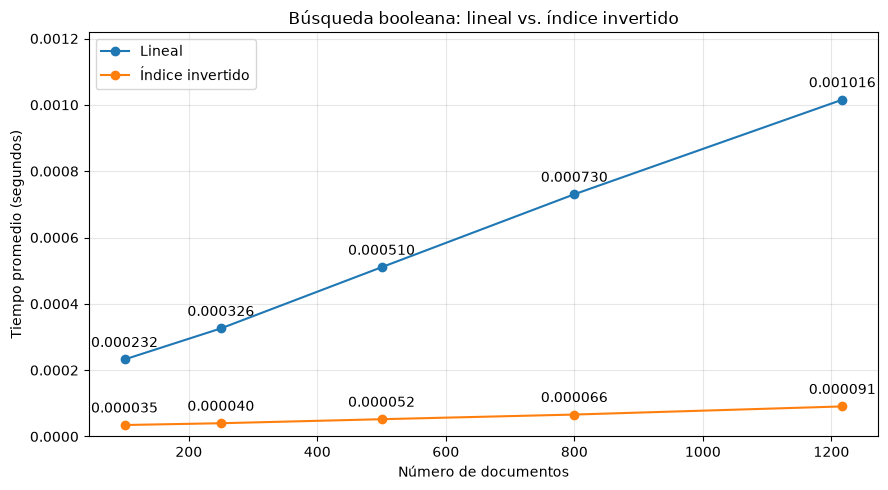

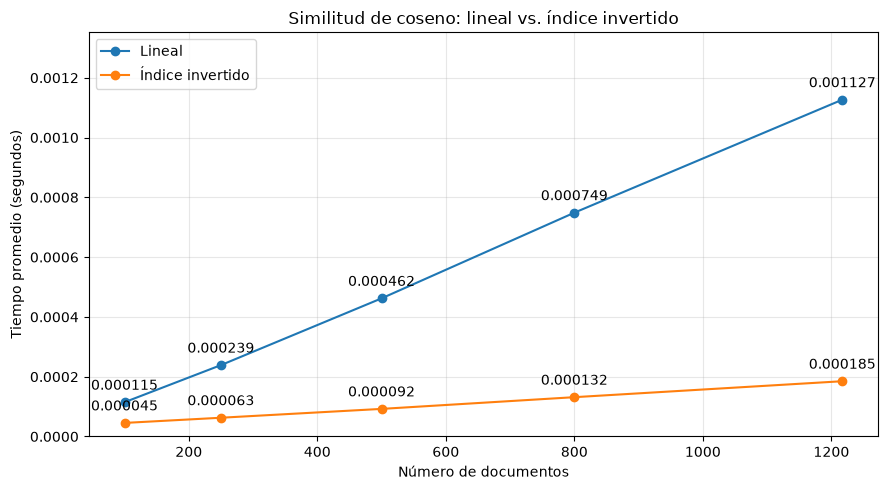

In [7]:
import time

import matplotlib.pyplot as plt


def build_sample_index(dataframe):
    sample = InvertedIndex()
    for row in dataframe.itertuples(index=False):
        sample._docs[row.id] = row.contenido
        sample._bows[row.id] = row.bag_of_words
        for term, frequency in row.bag_of_words.items():
            sample.index.setdefault(term, []).append((row.id, frequency))

    doc_count = len(dataframe)
    lengths_squared = {doc_id: 0.0 for doc_id in sample._docs}
    for term, postings in sample.index.items():
        weight = math.log10(doc_count / len(postings))
        sample.idf[term] = weight
        for doc_id, frequency in postings:
            lengths_squared[doc_id] += (tf_weight(frequency) * weight) ** 2
    sample.length = {
        doc_id: math.sqrt(value) for doc_id, value in lengths_squared.items()
    }
    return sample


def average_time(action, repetitions):
    action()
    start = time.perf_counter()
    for _ in range(repetitions):
        action()
    return (time.perf_counter() - start) / repetitions


sizes = [100, 250, 500, 800, len(noticias_bow_df)]
repetitions = 100
boolean_query = 'economía AND inflación'
cosine_query = 'sostenibilidad y energías renovables'
results = []

for size in sizes:
    subset = noticias_bow_df.head(size)
    start = time.perf_counter()
    sample_idx = build_sample_index(subset)
    build_seconds = time.perf_counter() - start

    boolean_linear = lambda: boolean_search_linear(boolean_query, subset)
    boolean_index = lambda: AND(sample_idx.L('economía'), sample_idx.L('inflación'))
    cosine_linear = lambda: sample_idx.cosine_search_linear(cosine_query, 5)
    cosine_index = lambda: sample_idx.cosine_search(cosine_query, 5)

    assert boolean_linear() == [doc_id for doc_id, _ in boolean_index()]
    linear_top = cosine_linear()
    index_top = cosine_index()
    assert [doc_id for doc_id, _ in linear_top] == [doc_id for doc_id, _ in index_top]
    assert all(math.isclose(a, b) for (_, a), (_, b) in zip(linear_top, index_top))

    results.append({
        'Documentos': size,
        'Construcción índice (s)': build_seconds,
        'Booleana lineal (s)': average_time(boolean_linear, repetitions),
        'Booleana índice (s)': average_time(boolean_index, repetitions),
        'Coseno lineal (s)': average_time(cosine_linear, repetitions),
        'Coseno índice (s)': average_time(cosine_index, repetitions),
    })

results_df = pd.DataFrame(results)
print('Consulta booleana:', boolean_query)
print('Consulta de coseno:', cosine_query)
print('Repeticiones por búsqueda:', repetitions)
display(results_df.round(6))


def plot_times(dataframe, linear_column, index_column, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    x = dataframe['Documentos']
    for column, label, offset in [
        (linear_column, 'Lineal', 9),
        (index_column, 'Índice invertido', 9),
    ]:
        y = dataframe[column]
        ax.plot(x, y, marker='o', label=label)
        for size, value in zip(x, y):
            ax.annotate(
                f'{value:.6f}', (size, value),
                textcoords='offset points', xytext=(0, offset), ha='center'
            )
    ax.set_title(title)
    ax.set_xlabel('Número de documentos')
    ax.set_ylabel('Tiempo promedio (segundos)')
    ax.set_ylim(0, max(dataframe[linear_column].max(), dataframe[index_column].max()) * 1.2)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


plot_times(results_df, 'Booleana lineal (s)', 'Booleana índice (s)',
           'Búsqueda booleana: lineal vs. índice invertido')
plot_times(results_df, 'Coseno lineal (s)', 'Coseno índice (s)',
           'Similitud de coseno: lineal vs. índice invertido')


## 6. Análisis de resultados

La tabla resume una ejecución con 100 repeticiones por búsqueda. Los tiempos están en segundos y pueden variar al repetir el experimento. La construcción del índice se midió por separado y no está incluida en los tiempos de consulta. En coseno se usó `log10(1 + tf) × log10(N / df)` para los documentos y la consulta; los términos presentes en toda la colección tienen IDF cero.

| Noticias | Construcción | Booleana lineal | Booleana índice | Coseno lineal | Coseno índice |
|---:|---:|---:|---:|---:|---:|
| 100 | 0,004975 | 0,000232 | 0,000035 | 0,000115 | 0,000045 |
| 250 | 0,013226 | 0,000326 | 0,000040 | 0,000239 | 0,000063 |
| 500 | 0,068829 | 0,000510 | 0,000052 | 0,000462 | 0,000092 |
| 800 | 0,039797 | 0,000730 | 0,000066 | 0,000749 | 0,000132 |
| 1 217 | 0,063254 | 0,001016 | 0,000091 | 0,001127 | 0,000185 |

**1. Complejidad.** La búsqueda booleana lineal revisa los N documentos y consulta dos claves de cada BoW, por lo que su costo es O(N) para esta consulta fija. Con índice, obtener las listas cuesta O(1) promedio por término y mezclarlas con dos punteros cuesta O(df₁ + df₂), donde df es el número de documentos que contienen cada término. La booleana lineal pasó de 0,000232 s con 100 noticias a 0,001016 s con 1 217; la indexada pasó de 0,000035 s a 0,000091 s. En coseno, el método lineal examina todos los documentos: cuesta O(N·q + C log C), con q términos de consulta y C documentos con puntaje positivo. El índice procesa las listas de los términos consultados y ordena sus candidatos: O(Σdf(t) + C log C). Sus tiempos pasaron de 0,000045 s a 0,000185 s, frente a 0,000115 s a 0,001127 s del lineal. La tendencia concuerda con estas complejidades, aunque los tamaños son pequeños y también influyen los costos fijos de Python.

**2. Punto de quiebre.** En los cinco tamaños probados, el índice fue más rápido en ambas búsquedas. Ya con 100 noticias, la booleana indexada tardó 0,000035 s frente a 0,000232 s de la lineal; en coseno fueron 0,000045 s frente a 0,000115 s. Por tanto, dentro del rango observado el índice supera al recorrido lineal desde el primer tamaño. No se midieron colecciones menores de 100 noticias, así que no puedo determinar el punto de cruce exacto ni afirmar que sea el mismo para booleana y coseno. En los tamaños observados ambos enfoques indexados aventajan a los lineales desde 100, pero los puntos de cruce exactos podrían ser distintos.

**3. Costo adicional.** Construir el índice requirió 0,004975 s para 100 noticias. Como cada consulta booleana ahorró aproximadamente 0,000197 s, las cifras redondeadas indican unas 26 consultas iguales para recuperar ese costo inicial. Para coseno el ahorro fue de unos 0,000070 s, equivalente a unas 72 consultas. Además de construir listas, se calculan IDF y normas y se mantienen diccionarios en memoria. Por eso la comparación de latencia favorece al índice, pero una aplicación que construya el índice para una sola consulta pequeña puede tardar más en total. Los tiempos de construcción fluctúan, como se ve al comparar 500 y 800 noticias, por lo que esas cantidades de amortización son estimaciones.

**4. Exactitud.** Para cada uno de los cinco tamaños, el experimento comprobó que la búsqueda booleana devolvió los mismos IDs con ambos enfoques. En coseno coincidieron también los cinco primeros IDs y sus puntajes dentro de la tolerancia de `math.isclose`: se contrastaron 25 posiciones en total. Ambos métodos usan el mismo TF logarítmico, IDF y normas; solo cambia qué documentos se visitan. Si alguna cifra final del puntaje difiere, se debe al orden de acumulación de números de punto flotante, no a una diferencia en los documentos relevantes. En las tres consultas de ejemplo también coincidieron los cinco primeros IDs.

**5. Límite de memoria.** Con 1 217 noticias se construyeron 12 772 términos distintos y 171 050 entradas en las listas de publicaciones. Si la colección creciera 100 veces y conservara una densidad parecida, habría alrededor de 121 700 noticias y 17 millones de entradas. Guardarlas como listas, tuplas y diccionarios de Python, junto con los textos, IDF, normas y BoW, consumiría mucha más RAM que los datos compactos y haría costosa la reconstrucción del índice. Una alternativa es SPIMI: formar bloques de índice que quepan en memoria, volcarlos a disco y fusionarlos después. Así se evita exigir que todas las listas estén residentes en RAM; para consultas frecuentes se pueden mantener en memoria solo el vocabulario y los bloques más usados.
